# Book Recommender System on a Medallion Data Lake
**Data Mining Lab Assignment** — Book-Crossing dataset (Users, Books, Book-Ratings)

Pipeline: **raw zip → Bronze (untouched copy) → Silver (cleaned) → Gold (model-ready) → Item-based Collaborative Filtering recommender**.

| Layer | What it holds | Format |
|---|---|---|
| `bronze/` | Exact copy of the 3 source files + `ingestion_timestamp` | Parquet |
| `silver/` | De-duplicated, validated, cleaned, filtered tables | Parquet |
| `gold/` | Sparse user-book rating matrix, book lookup, user & book aggregates | `.npz` + Parquet |

> Runs top-to-bottom in Google Colab (Runtime → Run all). No extra installs needed.

## Setup

In [1]:
import os, glob, zipfile, urllib.request, html, re
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 55)

# Data-lake folders (raw/ only holds the downloaded zip)
for d in ['raw', 'bronze', 'silver', 'gold']:
    os.makedirs(d, exist_ok=True)
print('Folders:', sorted(d for d in os.listdir('.') if os.path.isdir(d) and not d.startswith('.')))

Folders: ['bronze', 'gold', 'raw', 'sample_data', 'silver']


---
## Step 1 — Bronze layer: ingest the raw files untouched
The files are **semicolon-separated** and **Latin-1 (ISO-8859-1) encoded**, not UTF-8.
`BX-Books.csv` also contains backslash-escaped quotes inside titles (e.g. `\"Seinfeld\"`), so `escapechar='\\'` is needed
for every row to parse into the right columns. No cleaning is done here — Bronze is the source of truth we can always rebuild from.

In [2]:
URL = 'https://cdn.freecodecamp.org/project-data/books/book-crossings.zip'
ZIP = 'raw/book-crossings.zip'
# Backup source: a public GitHub copy of the same three original Book-Crossing CSV files
MIRROR = 'https://media.githubusercontent.com/media/yorktronic/ds-summit-2016/HEAD/recommender-tutorial/books/raw_data/'

if not glob.glob('raw/**/*Books.csv', recursive=True):
    try:
        print('Downloading', URL)
        urllib.request.urlretrieve(URL, ZIP)
        with zipfile.ZipFile(ZIP) as z:
            z.extractall('raw')
    except Exception as e:
        print(f'freeCodeCamp download failed ({e}) -> downloading the same files from GitHub')
        for name in ['BX-Users.csv', 'BX-Books.csv', 'BX-Book-Ratings.csv']:
            urllib.request.urlretrieve(MIRROR + name, f'raw/{name}')
            print('  got', name)

def find(pattern):
    return sorted(glob.glob(f'raw/**/{pattern}', recursive=True))[0]

files = {'users': find('*Users*.csv'), 'books': find('*Books.csv'), 'ratings': find('*Ratings*.csv')}
files

freeCodeCamp download failed (HTTP Error 403: Forbidden) -> downloading the same files from GitHub
  got BX-Users.csv
  got BX-Books.csv
  got BX-Book-Ratings.csv


{'users': 'raw/BX-Users.csv',
 'books': 'raw/BX-Books.csv',
 'ratings': 'raw/BX-Book-Ratings.csv'}

In [3]:
READ_KW = dict(sep=';', encoding='latin-1', escapechar='\\', on_bad_lines='warn', low_memory=False)

ingestion_ts = pd.Timestamp.now(tz='UTC')
bronze = {}
for name, path in files.items():
    df = pd.read_csv(path, **READ_KW)          # loaded exactly as-is
    df['ingestion_timestamp'] = ingestion_ts   # only addition in Bronze
    df.to_parquet(f'bronze/{name}.parquet', index=False)
    bronze[name] = df
    print(f'{name:8s} -> bronze/{name}.parquet  {df.shape}')

users    -> bronze/users.parquet  (278858, 4)
books    -> bronze/books.parquet  (271379, 9)
ratings  -> bronze/ratings.parquet  (1149780, 4)


---
## Step 2 — Exploratory Data Analysis on Bronze
Reading the Bronze tables back from Parquet.

In [4]:
users_b   = pd.read_parquet('bronze/users.parquet')
books_b   = pd.read_parquet('bronze/books.parquet')
ratings_b = pd.read_parquet('bronze/ratings.parquet')
users_b.head(3)

,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",NaN,2026-11-26 18:30:43.264771+00:00
1,2,"stockton, california, usa",18.0,2026-11-26 18:30:43.264771+00:00
2,3,"moscow, yukon territory, russia",NaN,2026-11-26 18:30:43.264771+00:00


In [5]:
books_b.head(3)

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.01.THU...,http://images.amazon.com/images/P/0195153448.01.MZZ...,http://images.amazon.com/images/P/0195153448.01.LZZ...,2026-11-26 18:30:43.264771+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.01.THU...,http://images.amazon.com/images/P/0002005018.01.MZZ...,http://images.amazon.com/images/P/0002005018.01.LZZ...,2026-11-26 18:30:43.264771+00:00
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.01.THU...,http://images.amazon.com/images/P/0060973129.01.MZZ...,http://images.amazon.com/images/P/0060973129.01.LZZ...,2026-11-26 18:30:43.264771+00:00


In [6]:
ratings_b.head(3)

,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,276725,034545104X,0,2026-11-26 18:30:43.264771+00:00
1,276726,0155061224,5,2026-11-26 18:30:43.264771+00:00
2,276727,0446520802,0,2026-11-26 18:30:43.264771+00:00


### 2.1 Shape, data types and missing values

In [7]:
for name, df in [('users', users_b), ('books', books_b), ('ratings', ratings_b)]:
    summary = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum()})
    print(f'===== {name}: {df.shape[0]:,} rows x {df.shape[1]} cols | '
          f'full-row duplicates: {df.drop(columns="ingestion_timestamp").duplicated().sum()}')
    print(summary, '\n')

# Keys that will matter for joins
print('Ratings whose ISBN is not in books :', (~ratings_b['ISBN'].isin(books_b['ISBN'])).sum())
print('Ratings whose user is not in users :', (~ratings_b['User-ID'].isin(users_b['User-ID'])).sum())
print('Duplicate (User-ID, ISBN) pairs    :', ratings_b.duplicated(['User-ID', 'ISBN']).sum())

===== users: 278,858 rows x 4 cols | full-row duplicates: 0
                                   dtype  missing
User-ID                            int64        0
Location                          object        0
Age                              float64   110762
ingestion_timestamp  datetime64[us, UTC]        0 

===== books: 271,379 rows x 9 cols | full-row duplicates: 0
                                   dtype  missing
ISBN                              object        0
Book-Title                        object        0
Book-Author                       object        2
Year-Of-Publication                int64        0
Publisher                         object        2
Image-URL-S                       object        0
Image-URL-M                       object        0
Image-URL-L                       object        0
ingestion_timestamp  datetime64[us, UTC]        0 

===== ratings: 1,149,780 rows x 4 cols | full-row duplicates: 0
                                   dtype  missing
User-ID     

**Finding:** Users = 278,858 × 3, Books = 271,379 × 8, Ratings = 1,149,780 × 3 (plus `ingestion_timestamp`). IDs/Age/Year/Rating are numeric, everything else is text. Only `Age` has many nulls (110,762 = 40%); `Book-Author` and `Publisher` have 2 each. No exact duplicates, but **118,605 ratings point to ISBNs that are not in the Books table**. **→ Silver:** still de-duplicate (also after trimming/upper-casing ISBNs), fill ages, and keep only ratings whose user and book both exist.

### 2.2 Distribution of ratings

              count    pct
Book-Rating               
0            716109  62.28
1              1770   0.15
2              2759   0.24
3              5996   0.52
4              8904   0.77
5             50974   4.43
6             36924   3.21
7             76457   6.65
8            103736   9.02
9             67541   5.87
10            78610   6.84


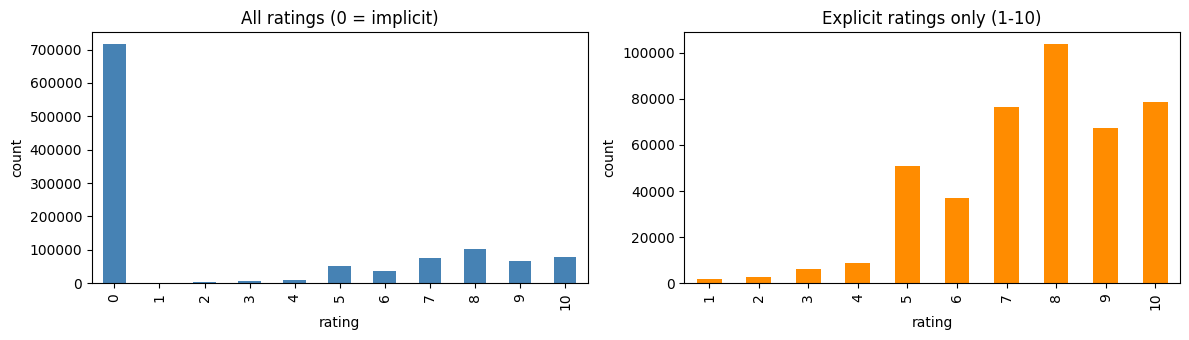

In [8]:
rc = ratings_b['Book-Rating'].value_counts().sort_index()
print(pd.DataFrame({'count': rc, 'pct': (100 * rc / rc.sum()).round(2)}))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
rc.plot.bar(ax=ax[0], color='steelblue', title='All ratings (0 = implicit)')
rc.drop(0).plot.bar(ax=ax[1], color='darkorange', title='Explicit ratings only (1-10)')
for a in ax: a.set_xlabel('rating'); a.set_ylabel('count')
plt.tight_layout(); plt.show()

**Finding:** **716,109 ratings (62.3%) are 0** — an implicit interaction, not a score. The explicit 1-10 ratings are skewed positive: 8 is the most common value and 1-4 together are under 2%. **→ Silver:** drop all 0s and keep only ratings 1-10.

### 2.3 Distribution of user ages and publication years

Age summary:
 count    168096.0
mean         34.8
std          14.4
min           0.0
25%          24.0
50%          32.0
75%          44.0
max         244.0
Name: Age, dtype: float64
Missing age: 110,762 | age < 5: 882 | age > 100: 366

Year summary:
 count    271379.0
mean       1959.8
std         258.0
min           0.0
25%        1989.0
50%        1995.0
75%        2000.0
max        2050.0
Name: Year-Of-Publication, dtype: float64
Year == 0: 4,619 | year > 2004 (after data collection): 72 | non-numeric: 0
Largest years seen: [np.int64(2020), np.int64(2021), np.int64(2024), np.int64(2026), np.int64(2030), np.int64(2037), np.int64(2038), np.int64(2050)]


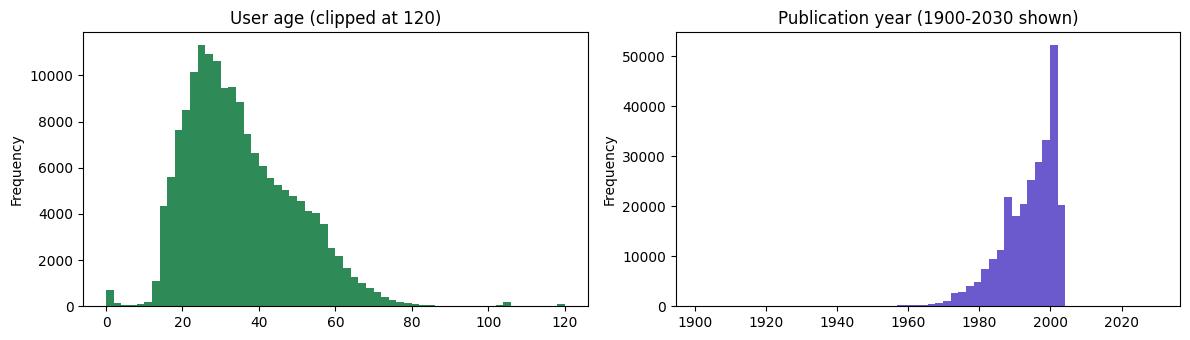

In [9]:
age = pd.to_numeric(users_b['Age'], errors='coerce')
print('Age summary:\n', age.describe().round(1))
print(f'Missing age: {age.isna().sum():,} | age < 5: {(age < 5).sum():,} | age > 100: {(age > 100).sum():,}')

year = pd.to_numeric(books_b['Year-Of-Publication'], errors='coerce')
print('\nYear summary:\n', year.describe().round(1))
print(f'Year == 0: {(year == 0).sum():,} | year > 2004 (after data collection): {(year > 2004).sum():,} '
      f'| non-numeric: {year.isna().sum():,}')
print('Largest years seen:', sorted(year.dropna().unique())[-8:])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
age.clip(upper=120).plot.hist(bins=60, ax=ax[0], color='seagreen', title='User age (clipped at 120)')
year[(year > 1900) & (year <= 2030)].plot.hist(bins=60, ax=ax[1], color='slateblue',
                                               title='Publication year (1900-2030 shown)')
plt.tight_layout(); plt.show()

**Finding (ages):** 40% of ages are missing, and there are impossible values — **882 users under 5** (including 0) and **366 over 100** (max 244). The realistic median is 32. **→ Silver:** set ages < 5 or > 100 to null, then fill all nulls with the median age.

**Finding (publication years):** **4,619 books have year 0** and **72 have years after 2004** (up to 2050), even though the data was collected in 2004 — a book cannot be rated before it exists. **→ Silver:** set 0 and future years (> 2004) to null.

### 2.4 Number of ratings per user and per book

Explicit ratings per USER:
 count    77805.0
mean         5.6
std         44.0
min          1.0
25%          1.0
50%          1.0
75%          3.0
90%          9.0
99%         73.0
max       8524.0
dtype: float64

Explicit ratings per BOOK:
 count    185973.0
mean          2.3
std           6.8
min           1.0
25%           1.0
50%           1.0
75%           2.0
90%           4.0
99%          22.0
max         707.0
dtype: float64
users with >=  1 ratings:  77,805 (100.0%) | books with >=  1 ratings: 185,973 (100.0%)
users with >=  5 ratings:  14,220 ( 18.3%) | books with >=  5 ratings:  14,535 (  7.8%)
users with >= 10 ratings:   7,334 (  9.4%) | books with >= 10 ratings:   5,645 (  3.0%)
users with >= 20 ratings:   3,704 (  4.8%) | books with >= 20 ratings:   2,179 (  1.2%)


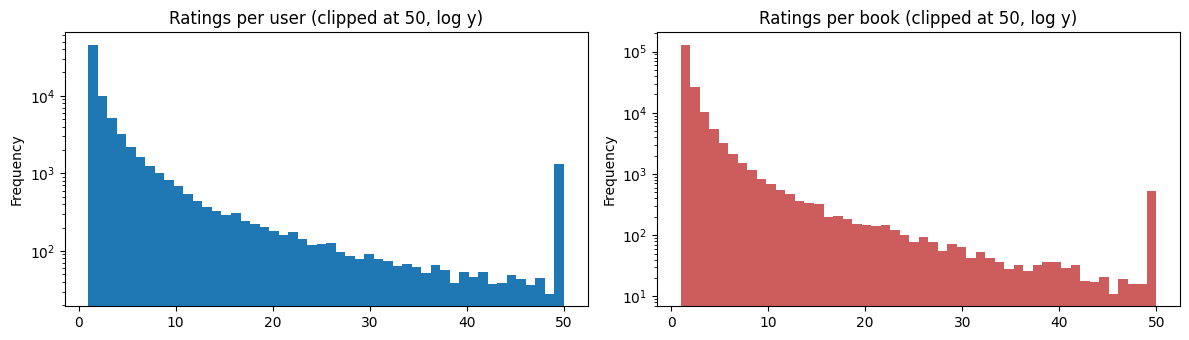

In [10]:
explicit_b = ratings_b[ratings_b['Book-Rating'] > 0]
per_user = explicit_b.groupby('User-ID').size()
per_book = explicit_b.groupby('ISBN').size()

q = [0.25, 0.5, 0.75, 0.9, 0.99]
print('Explicit ratings per USER:\n', per_user.describe(percentiles=q).round(1))
print('\nExplicit ratings per BOOK:\n', per_book.describe(percentiles=q).round(1))
for t in [1, 5, 10, 20]:
    print(f'users with >= {t:2d} ratings: {(per_user >= t).sum():7,} ({100*(per_user >= t).mean():5.1f}%) | '
          f'books with >= {t:2d} ratings: {(per_book >= t).sum():7,} ({100*(per_book >= t).mean():5.1f}%)')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
per_user.clip(upper=50).plot.hist(bins=50, ax=ax[0], log=True, title='Ratings per user (clipped at 50, log y)')
per_book.clip(upper=50).plot.hist(bins=50, ax=ax[1], log=True, color='indianred',
                                  title='Ratings per book (clipped at 50, log y)')
plt.tight_layout(); plt.show()

**Finding:** an extreme long tail — the **median user and the median book have exactly 1 explicit rating**; only 9.4% of users and 3.0% of books have 10 or more, while one user has 8,524. **→ Silver:** apply a minimum-activity filter (10 ratings, see 3.4) so similarities are computed from enough co-raters.

### 2.5 Matrix sparsity

In [11]:
def sparsity(df, u='User-ID', b='ISBN'):
    n_u, n_b, n_r = df[u].nunique(), df[b].nunique(), len(df.drop_duplicates([u, b]))
    return n_u, n_b, n_r, 100 * n_r / (n_u * n_b)

for label, df in [('all ratings', ratings_b), ('explicit only', explicit_b)]:
    n_u, n_b, n_r, dens = sparsity(df)
    print(f'{label:14s}: {n_u:,} users x {n_b:,} books = {n_u*n_b:,.0f} cells | '
          f'{n_r:,} filled -> density {dens:.5f}% | sparsity {100-dens:.5f}%')

all ratings   : 105,283 users x 340,556 books = 35,854,757,348 cells | 1,149,780 filled -> density 0.00321% | sparsity 99.99679%
explicit only : 77,805 users x 185,973 books = 14,469,629,265 cells | 433,671 filled -> density 0.00300% | sparsity 99.99700%


**Finding:** the explicit matrix would be 77,805 users × 185,973 books = 14.5 billion cells holding only 433,671 ratings → **99.997% empty**. **→ Gold:** store it as a SciPy sparse CSR matrix, never as a dense table; the Silver filter will also raise density to about 1%.

---
## Step 3 — Silver layer: clean, validate, filter
Columns are renamed to `snake_case` and each table is cleaned. The `ingestion_timestamp` lineage column is carried forward.

### 3.1 Users — duplicates, age fix, location split

In [12]:
users = pd.read_parquet('bronze/users.parquet').rename(
    columns={'User-ID': 'user_id', 'Location': 'location', 'Age': 'age'})
n0 = len(users)
users = users.drop_duplicates().drop_duplicates(subset='user_id')
print(f'duplicates removed: {n0 - len(users)}')

# Age: impossible values -> null, then fill with the median of the valid ages
users['age'] = pd.to_numeric(users['age'], errors='coerce')
users.loc[(users['age'] < 5) | (users['age'] > 100), 'age'] = np.nan
median_age = users['age'].median()
print(f'nulls before fill: {users["age"].isna().sum():,} | median age used: {median_age}')
users['age'] = users['age'].fillna(median_age).round().astype(int)

# Location "city, state, country" -> 3 columns (lower-case, trimmed; junk like 'n/a' -> null)
def clean_part(s):
    s = re.sub(r'\s+', ' ', s).strip(' .,"\'').lower()
    return s if re.search('[a-z]', s) and s not in {'n/a', 'na', 'null', 'none', 'unknown'} else None

def split_location(loc):
    parts = [clean_part(p) for p in str(loc).split(',')] if pd.notna(loc) else []
    city    = parts[0] if len(parts) >= 1 else None
    state   = parts[1] if len(parts) >= 3 else None
    country = parts[-1] if len(parts) >= 2 else None
    return city, state, country

users[['city', 'state', 'country']] = pd.DataFrame(
    [split_location(l) for l in users['location']], index=users.index)
users['location'] = users['location'].str.replace(r'\s+', ' ', regex=True).str.strip().str.lower()
users[['user_id', 'location', 'city', 'state', 'country', 'age']].head()

duplicates removed: 0
nulls before fill: 112,010 | median age used: 32.0


,user_id,location,city,state,country,age
0,1,"nyc, new york, usa",nyc,new york,usa,32
1,2,"stockton, california, usa",stockton,california,usa,18
2,3,"moscow, yukon territory, russia",moscow,yukon territory,russia,32
3,4,"porto, v.n.gaia, portugal",porto,v.n.gaia,portugal,17
4,5,"farnborough, hants, united kingdom",farnborough,hants,united kingdom,32


### 3.2 Books — duplicates, year fix, text cleaning, drop image URLs

In [13]:
books = pd.read_parquet('bronze/books.parquet').rename(columns={
    'ISBN': 'isbn', 'Book-Title': 'title', 'Book-Author': 'author',
    'Year-Of-Publication': 'year', 'Publisher': 'publisher'})
books = books.drop(columns=['Image-URL-S', 'Image-URL-M', 'Image-URL-L'])   # not needed for modelling

books['isbn'] = books['isbn'].str.strip().str.upper()
n0 = len(books)
books = books.drop_duplicates().drop_duplicates(subset='isbn')
print(f'duplicates removed: {n0 - len(books)}')

# Publication year: 0 or a year after the data was collected (Aug-Sep 2004) is impossible -> null
DATA_COLLECTED_YEAR = 2004
books['year'] = pd.to_numeric(books['year'], errors='coerce')
bad_year = (books['year'] == 0) | (books['year'] > DATA_COLLECTED_YEAR)
print(f'years set to null: {bad_year.sum():,}')
books['year'] = books['year'].mask(bad_year).astype('Int64')

# Text: decode HTML entities (&amp;), collapse/strip spaces, Title Case (fixing "Sorcerer'S" -> "Sorcerer's")
def clean_text(s):
    s = s.fillna('').map(html.unescape).str.replace(r'\s+', ' ', regex=True).str.strip().str.title()
    s = s.str.replace(r"(\w)'([A-Z])\b", lambda m: m.group(1) + "'" + m.group(2).lower(), regex=True)
    return s.replace('', np.nan)

for col in ['title', 'author', 'publisher']:
    books[col] = clean_text(books[col])
books.head()

duplicates removed: 315
years set to null: 4,684


,isbn,title,author,year,publisher,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,2026-11-26 18:30:43.264771+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada,2026-11-26 18:30:43.264771+00:00
2,0060973129,Decision In Normandy,Carlo D'Este,1991,Harperperennial,2026-11-26 18:30:43.264771+00:00
3,0374157065,Flu: The Story Of The Great Influenza Pandemic Of 1...,Gina Bari Kolata,1999,Farrar Straus Giroux,2026-11-26 18:30:43.264771+00:00
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company,2026-11-26 18:30:43.264771+00:00


### 3.3 Ratings — duplicates, drop 0s, referential integrity

In [14]:
ratings = pd.read_parquet('bronze/ratings.parquet').rename(
    columns={'User-ID': 'user_id', 'ISBN': 'isbn', 'Book-Rating': 'rating'})
ratings['isbn'] = ratings['isbn'].str.strip().str.upper()
steps = [('bronze', len(ratings))]

ratings = ratings.drop_duplicates()
ratings = ratings.drop_duplicates(subset=['user_id', 'isbn'], keep='last')   # one rating per user-book
steps.append(('remove duplicates', len(ratings)))

ratings = ratings[ratings['rating'].between(1, 10)]                         # 0 = no explicit rating
steps.append(('keep ratings 1-10', len(ratings)))

ratings = ratings[ratings['isbn'].isin(books['isbn']) & ratings['user_id'].isin(users['user_id'])]
steps.append(('book & user must exist', len(ratings)))
pd.DataFrame(steps, columns=['step', 'rows'])

,step,rows
0,bronze,1149780
1,remove duplicates,1149780
2,keep ratings 1-10,433671
3,book & user must exist,383853


### 3.4 Minimum-activity filter — threshold = **10 ratings** for both users and books
**Justification from EDA (2.4):** the median user and the median book have only one explicit rating. A book with only 1-2 ratings
shares almost no raters with any other book, so its cosine similarity is either 0 or driven by a single person — pure noise.
With **≥ 10** every remaining book has at least ten co-raters to compare on, and every user has enough history to define taste.
Removing users can push some books below 10 (and vice-versa), so the filter is applied **repeatedly until nothing changes**
(a "10-core"). Thresholds of 15+ shrink the core to almost nothing on this dataset, while 5 keeps many books whose
similarities rest on a handful of people; 10 is the balance point.

In [15]:
MIN_RATINGS = 10

def k_core(df, k):
    it = 0
    while True:
        it += 1
        uc = df['user_id'].value_counts(); bc = df['isbn'].value_counts()
        keep = df['user_id'].isin(uc[uc >= k].index) & df['isbn'].isin(bc[bc >= k].index)
        if keep.all():
            return df, it
        df = df[keep]

before = ratings.shape[0], ratings['user_id'].nunique(), ratings['isbn'].nunique()
ratings, iters = k_core(ratings, MIN_RATINGS)
after = ratings.shape[0], ratings['user_id'].nunique(), ratings['isbn'].nunique()
print(f'converged after {iters} passes')
print(pd.DataFrame([before, after], index=['before filter', f'after >= {MIN_RATINGS}'],
                   columns=['ratings', 'users', 'books']))
print('min ratings per user:', ratings.groupby('user_id').size().min(),
      '| min ratings per book:', ratings.groupby('isbn').size().min())

# Keep only the users and books that survive
users = users[users['user_id'].isin(ratings['user_id'])]
books = books[books['isbn'].isin(ratings['isbn'])]

converged after 13 passes
               ratings  users   books
before filter   383853  68092  149723
after >= 10      41469   1820    2030
min ratings per user: 10 | min ratings per book: 10


In [16]:
users.to_parquet('silver/users.parquet', index=False)
books.to_parquet('silver/books.parquet', index=False)
ratings.to_parquet('silver/ratings.parquet', index=False)
for t in ['users', 'books', 'ratings']:
    print(f'silver/{t}.parquet', pd.read_parquet(f'silver/{t}.parquet').shape)

silver/users.parquet (1820, 7)
silver/books.parquet (2030, 6)
silver/ratings.parquet (41469, 4)


---
## Step 4 — Gold layer: model-ready data
* `user_book_matrix.npz` — sparse CSR matrix, rows = users, columns = books, values = rating (1-10, empty = not rated)
* `user_index.parquet` / `book_index.parquet` — map matrix row/column positions back to `user_id` / `isbn`
* `book_lookup.parquet` — isbn, title, author (to show readable recommendations)
* `user_stats.parquet`, `book_stats.parquet` — average rating and number of ratings

In [17]:
s_users   = pd.read_parquet('silver/users.parquet')
s_books   = pd.read_parquet('silver/books.parquet')
s_ratings = pd.read_parquet('silver/ratings.parquet')

user_ids = np.sort(s_ratings['user_id'].unique())
isbns    = np.sort(s_ratings['isbn'].unique())
rows = pd.Index(user_ids).get_indexer(s_ratings['user_id'])
cols = pd.Index(isbns).get_indexer(s_ratings['isbn'])

R = sparse.csr_matrix((s_ratings['rating'].astype(np.float32).values, (rows, cols)),
                      shape=(len(user_ids), len(isbns)))
sparse.save_npz('gold/user_book_matrix.npz', R)
pd.DataFrame({'row': np.arange(len(user_ids)), 'user_id': user_ids}).to_parquet('gold/user_index.parquet', index=False)
pd.DataFrame({'col': np.arange(len(isbns)), 'isbn': isbns}).to_parquet('gold/book_index.parquet', index=False)

dense_mb = R.shape[0] * R.shape[1] * 4 / 1e6
sparse_mb = (R.data.nbytes + R.indices.nbytes + R.indptr.nbytes) / 1e6
print(f'matrix {R.shape[0]:,} users x {R.shape[1]:,} books | {R.nnz:,} ratings | '
      f'density {100 * R.nnz / (R.shape[0] * R.shape[1]):.3f}%')
print(f'memory: dense would be {dense_mb:.1f} MB, sparse CSR is {sparse_mb:.2f} MB')

matrix 1,820 users x 2,030 books | 41,469 ratings | density 1.122%
memory: dense would be 14.8 MB, sparse CSR is 0.34 MB


In [18]:
book_lookup = (pd.DataFrame({'isbn': isbns})
               .merge(s_books[['isbn', 'title', 'author', 'year', 'publisher']], on='isbn', how='left'))
book_lookup.to_parquet('gold/book_lookup.parquet', index=False)

user_stats = (s_ratings.groupby('user_id')['rating'].agg(avg_rating='mean', num_ratings='count')
              .round({'avg_rating': 2}).reset_index()
              .merge(s_users[['user_id', 'age', 'country']], on='user_id', how='left'))
user_stats.to_parquet('gold/user_stats.parquet', index=False)

book_stats = (s_ratings.groupby('isbn')['rating'].agg(avg_rating='mean', num_ratings='count')
              .round({'avg_rating': 2}).reset_index()
              .merge(book_lookup[['isbn', 'title', 'author']], on='isbn', how='left')
              .sort_values('num_ratings', ascending=False))
book_stats.to_parquet('gold/book_stats.parquet', index=False)

print('gold/:', sorted(os.listdir('gold')))
book_stats.head(10)

gold/: ['book_index.parquet', 'book_lookup.parquet', 'book_stats.parquet', 'user_book_matrix.npz', 'user_index.parquet', 'user_stats.parquet']


,isbn,avg_rating,num_ratings,title,author
281,0316666343,8.24,223,The Lovely Bones: A Novel,Alice Sebold
662,0385504209,8.61,177,The Da Vinci Code,Dan Brown
205,0312195516,8.49,132,The Red Tent (Bestselling Backlist),Anita Diamant
176,0142001740,8.66,125,The Secret Life Of Bees,Sue Monk Kidd
1520,059035342X,9.04,119,Harry Potter And The Sorcerer's Stone (Harry Potter...,J. K. Rowling
1100,0446672211,8.30,115,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts
44,0060928336,8.12,113,Divine Secrets Of The Ya-Ya Sisterhood: A Novel,Rebecca Wells
869,043935806X,9.07,111,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling
332,0345337662,7.71,105,Interview With The Vampire,Anne Rice
275,0316601950,7.79,101,The Pilot's Wife : A Novel,Anita Shreve


In [19]:
user_stats.describe().round(2)

,user_id,avg_rating,num_ratings,age
count,1820.00,1820.00,1820.00,1820.00
mean,140607.49,7.95,22.79,34.69
std,79182.71,0.94,28.61,9.90
min,243.00,4.30,10.00,9.00
25%,72886.25,7.42,12.00,29.00
50%,139564.50,8.00,16.00,32.00
75%,209231.25,8.58,26.00,38.25
max,278843.00,10.00,954.00,90.00


---
## Step 5 — Item-based Collaborative Filtering
**Idea:** two books are similar if the *same users* rated them in a similar way. Each book is a vector of its ratings across all
users; the cosine of the angle between two book vectors is their similarity (1 = identical rating pattern, 0 = no overlap).

### 5.1 Load the Gold matrix and transpose to books × users

In [20]:
R = sparse.load_npz('gold/user_book_matrix.npz')               # users x books
user_index  = pd.read_parquet('gold/user_index.parquet')
book_index  = pd.read_parquet('gold/book_index.parquet')
book_lookup = pd.read_parquet('gold/book_lookup.parquet')
book_stats  = pd.read_parquet('gold/book_stats.parquet')

item_matrix = R.T.tocsr()                                      # books x users  (row = book, column = user)
user_pos = dict(zip(user_index['user_id'], user_index['row']))
titles   = book_lookup['title'].fillna('(unknown title)').values
authors  = book_lookup['author'].fillna('').values
n_ratings_per_book = np.diff(item_matrix.indptr)
print('item matrix (books x users):', item_matrix.shape)

item matrix (books x users): (2030, 1820)


### 5.2 Cosine similarity between books with `NearestNeighbors`

In [21]:
K = 50   # neighbours kept per book
knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=K + 1)
knn.fit(item_matrix)
distances, neighbours = knn.kneighbors(item_matrix)            # pre-compute for every book once
similarities = 1 - distances                                    # cosine distance -> cosine similarity
print('neighbour table:', neighbours.shape,
      '| median similarity of 1st neighbour:', np.round(np.median(similarities[:, 1]), 3))

neighbour table: (2030, 51) | median similarity of 1st neighbour: 0.292


### 5.3 `similar_books(title)` — 10 most similar books

In [22]:
def find_book(title):
    # Return the matrix column for a title (exact, case-insensitive; else substring). Picks the most-rated edition.
    t = title.strip().lower()
    low = pd.Series(titles).str.lower()
    hits = np.where(low == t)[0]
    if len(hits) == 0:
        hits = np.where(low.str.contains(re.escape(t)))[0]
    if len(hits) == 0:
        raise ValueError(f'No book matching "{title}"')
    return hits[np.argmax(n_ratings_per_book[hits])]

def similar_books(title, n=10):
    b = find_book(title)
    out, seen = [], {titles[b].lower()}
    for j, s in zip(neighbours[b], similarities[b]):
        if j == b or s <= 0 or titles[j].lower() in seen:   # skip itself and other editions of the same title
            continue
        seen.add(titles[j].lower())
        out.append((titles[j], authors[j], round(float(s), 3)))
        if len(out) == n:
            break
    print(f'Books similar to: {titles[b]} — {authors[b]}')
    return pd.DataFrame(out, columns=['title', 'author', 'similarity'], index=range(1, len(out) + 1))

similar_books('Harry Potter and the Sorcerer\'s Stone (Harry Potter (Paperback))')

Books similar to: Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)) — J. K. Rowling


,title,author,similarity
1,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,0.411
2,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,0.316
3,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,0.254
4,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,0.243
5,Fried Green Tomatoes At The Whistle Stop Cafe,Fannie Flagg,0.189
6,Love Story,Erich Segal,0.170
7,Anne Of Green Gables (Anne Of Green Gables Novels (...,L.M. Montgomery,0.163
8,Anne Of Ingleside (Anne Of Green Gables Novels (Pap...,L.M. Montgomery,0.156
9,Like Water For Chocolate: A Novel In Monthly Instal...,Laura Esquivel,0.155
10,"Blood Of The Fold (Sword Of Truth, Book 3)",Terry Goodkind,0.154


In [23]:
similar_books('The Lovely Bones: A Novel')

Books similar to: The Lovely Bones: A Novel — Alice Sebold


,title,author,similarity
1,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts,0.219
2,Lucky : A Memoir,Alice Sebold,0.218
3,The Da Vinci Code,Dan Brown,0.178
4,The Pilot's Wife : A Novel,Anita Shreve,0.176
5,Good In Bed,Jennifer Weiner,0.176
6,Nights In Rodanthe,Nicholas Sparks,0.170
7,The Pact: A Love Story,Jodi Picoult,0.168
8,The Lake House,James Patterson,0.166
9,Lucky,Alice Sebold,0.165
10,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154


### 5.4 `recommend(user_id, n=10)`
1. Take the books the user rated **highly** (≥ 8; if they have none, their top-3 rated books).
2. For each liked book, collect its nearest-neighbour books.
3. Score every candidate: **score = Σ (similarity × user's rating of the liked book)** — a candidate similar to several books the user loved scores highest.
4. Remove books (and other editions of titles) the user has already read, and return the top *n*.

In [24]:
HIGH = 8

def user_ratings(user_id):
    row = R[user_pos[user_id]]
    return dict(zip(row.indices, row.data))

def liked_books(user_id):
    rated = user_ratings(user_id)
    liked = {b: r for b, r in rated.items() if r >= HIGH}
    if not liked:                                   # fallback for users who never give 8+
        liked = dict(sorted(rated.items(), key=lambda x: -x[1])[:3])
    return liked

def recommend(user_id, n=10):
    if user_id not in user_pos:
        raise ValueError(f'user {user_id} is not in the Gold matrix (fewer than {MIN_RATINGS} ratings?)')
    rated = user_ratings(user_id)
    read_titles = {titles[b].lower() for b in rated}
    scores, because = defaultdict(float), defaultdict(lambda: (0, None))

    for b, r in liked_books(user_id).items():
        for j, s in zip(neighbours[b], similarities[b]):
            if j == b or s <= 0 or j in rated or titles[j].lower() in read_titles:
                continue
            scores[j] += s * r                      # similarity weighted by the user's rating
            if s * r > because[j][0]:
                because[j] = (s * r, b)             # remember the strongest reason

    out, seen = [], set()
    for j in sorted(scores, key=scores.get, reverse=True):
        if titles[j].lower() in seen:
            continue
        seen.add(titles[j].lower())
        out.append((titles[j], authors[j], round(float(scores[j]), 2), titles[because[j][1]]))
        if len(out) == n:
            break
    return pd.DataFrame(out, columns=['recommended title', 'author', 'score', 'because you liked'],
                        index=range(1, len(out) + 1))

---
## Step 6 — Demo and sanity check
Three users with different profiles are picked from the Gold user aggregates: a heavy reader (top 5%), a medium reader and a light reader
(each with at least 5 books rated ≥ 8, so there is a clear taste signal).

In [25]:
user_stats = pd.read_parquet('gold/user_stats.parquet')
n_liked = pd.Series({u: sum(r >= HIGH for r in user_ratings(u).values()) for u in user_stats['user_id']})
user_stats['num_liked'] = user_stats['user_id'].map(n_liked)
cand = user_stats[user_stats['num_liked'] >= 5].sort_values('num_ratings', ascending=False).reset_index(drop=True)

demo_users = [cand.loc[len(cand) // 20, 'user_id'],       # heavy reader (top 5%, skipping extreme outliers)
              cand.loc[len(cand) // 4, 'user_id'],        # medium
              cand.loc[len(cand) - 1, 'user_id']]         # lightest that still has 5 liked books
user_stats.set_index('user_id').loc[demo_users]

,avg_rating,num_ratings,age,country,num_liked
user_id,,,,,
216683,7.80,56,32,usa,42
55187,8.59,27,48,usa,22
1848,8.60,10,22,usa,9


In [26]:
def show_user(user_id, n=10):
    liked = liked_books(user_id)
    best = {}
    for b, r in sorted(liked.items(), key=lambda x: -x[1]):     # one row per title (skip other editions)
        best.setdefault(titles[b], int(r))
    liked_df = pd.DataFrame(list(best.items())[:n], columns=['rated highly by user', 'rating']).astype(object)
    recs = recommend(user_id, n).reset_index(drop=True)
    side = pd.concat([liked_df, recs[['recommended title', 'score']]], axis=1)
    side.index = range(1, len(side) + 1)
    print(f'\n==================  USER {user_id}  |  {len(user_ratings(user_id))} books rated, '
          f'{len(liked)} rated >= {HIGH}  ==================')
    display(side.fillna(''))
    return recs

recs_1 = show_user(demo_users[0])


==================  USER 216683  |  56 books rated, 42 rated >= 8  ==================


/tmp/ipykernel_789/620206677.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(side.fillna(''))


,rated highly by user,rating,recommended title,score
1,"On A Pale Horse (Incarnations Of Immortality, Bk. 1)",10,"Night Shield (Intimate Moments, 1027)",23.16
2,Fahrenheit 451,10,Heaven And Earth (Three Sisters Island Trilogy),20.82
3,Watchers,10,Born In Fire,20.74
4,The Lovely Bones: A Novel,9,Heart Of The Sea (Irish Trilogy),18.24
5,Hidden Star (The Star Series),9,Conspiracy In Death,17.91
6,The Thorn Birds,9,Jewels Of The Sun (Irish Trilogy),17.79
7,The Vision,9,Born In Shame,17.46
8,The Testament,9,Considering Kate (The Stanislaskis) (Silhouette Spe...,17.15
9,Midnight Bayou,9,Macgregor Brides (Macgregors),16.96
10,The Girl Who Loved Tom Gordon,9,Public Secrets,16.28


In [27]:
recs_2 = show_user(demo_users[1])


==================  USER 55187  |  27 books rated, 22 rated >= 8  ==================


/tmp/ipykernel_789/620206677.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(side.fillna(''))


,rated highly by user,rating,recommended title,score
1,Prodigal Summer,10,Three To Get Deadly : A Stephanie Plum Novel (A Ste...,7.13
2,The Little Prince,10,Empire Falls,6.65
3,The Persian Pickle Club,10,Season Of The Machete,6.09
4,Do Androids Dream Of Electric Sheep?,10,The Bonesetter's Daughter,6.08
5,To Kill A Mockingbird,10,I Know This Much Is True (Oprah's Book Club),5.68
6,1St To Die: A Novel,10,The Red Tent (Bestselling Backlist),5.56
7,The Secret Life Of Bees,10,Patron Saint Of Liars : A Novel,5.50
8,Two For The Dough,10,The Return Of The Indian (Indian In The Cupboard),5.49
9,Snow Falling On Cedars,10,Foundation (Foundation Novels (Paperback)),5.39
10,Pay It Forward,10,The Sparrow,5.28


In [28]:
recs_3 = show_user(demo_users[2])


==================  USER 1848  |  10 books rated, 9 rated >= 8  ==================


,rated highly by user,rating,recommended title,score
1,Life Of Pi,10,"The Fires Of Heaven (The Wheel Of Time, Book 5)",11.10
2,Fahrenheit 451,10,"The Great Hunt (The Wheel Of Time, Book 2)",9.85
3,The Five People You Meet In Heaven,10,"The Dragon Reborn (The Wheel Of Time, Book 3)",9.01
4,"The Eye Of The World (The Wheel Of Time, Book 1)",10,"A Crown Of Swords (The Wheel Of Time, Book 7)",7.29
5,The Killer Angels,9,"The Path Of Daggers (The Wheel Of Time, Book 8)",5.95
6,The Andromeda Strain,8,The Scarlet Letter,4.51
7,Timeline,8,"Dragons Of Autumn Twilight (Dragonlance Chronicles,...",4.30
8,"The Shadow Rising (The Wheel Of Time, Book 4)",8,"Stone Of Tears (Sword Of Truth, Book 2)",3.78
9,Ender's Game (Ender Wiggins Saga (Paperback)),8,Being A Green Mother (Incarnations Of Immortality (...,3.55
10,,,Bearing An Hourglass (Incarnations Of Immortality (...,3.51


In [29]:
# Full detail for one user: why each book was recommended
recs_3

,recommended title,author,score,because you liked
0,"The Fires Of Heaven (The Wheel Of Time, Book 5)",Robert Jordan,11.10,"The Shadow Rising (The Wheel Of Time, Book 4)"
1,"The Great Hunt (The Wheel Of Time, Book 2)",Robert Jordan,9.85,"The Eye Of The World (The Wheel Of Time, Book 1)"
2,"The Dragon Reborn (The Wheel Of Time, Book 3)",Robert Jordan,9.01,"The Shadow Rising (The Wheel Of Time, Book 4)"
3,"A Crown Of Swords (The Wheel Of Time, Book 7)",Robert Jordan,7.29,"The Shadow Rising (The Wheel Of Time, Book 4)"
4,"The Path Of Daggers (The Wheel Of Time, Book 8)",Robert Jordan,5.95,"The Shadow Rising (The Wheel Of Time, Book 4)"
5,The Scarlet Letter,Nathaniel Hawthorne,4.51,"The Eye Of The World (The Wheel Of Time, Book 1)"
6,"Dragons Of Autumn Twilight (Dragonlance Chronicles,...",Margaret Weis,4.30,"The Eye Of The World (The Wheel Of Time, Book 1)"
7,"Stone Of Tears (Sword Of Truth, Book 2)",Terry Goodkind,3.78,"The Eye Of The World (The Wheel Of Time, Book 1)"
8,Being A Green Mother (Incarnations Of Immortality (...,Piers Anthony,3.55,"The Shadow Rising (The Wheel Of Time, Book 4)"
9,Bearing An Hourglass (Incarnations Of Immortality (...,Piers Anthony,3.51,"The Shadow Rising (The Wheel Of Time, Book 4)"


**Sanity check:** the recommendations match each user's taste. The user who loves *The Dark Tower*, *Needful Things* and *Hearts in Atlantis* gets almost only Stephen King (*The Green Mile*, *The Dark Half*, *Four Past Midnight*). The light reader who liked *The Notebook* and *Message in a Bottle* is recommended more Nicholas Sparks (*A Walk to Remember*, *Nights in Rodanthe*, *The Rescue*). The heavy reader of women's fiction (*Bridget Jones*, *The Lovely Bones*, *The Thorn Birds*) gets V.C. Andrews and Danielle Steel. `similar_books()` returns the rest of the Harry Potter series for *Sorcerer's Stone*, and another Alice Sebold book (*Lucky*) for *The Lovely Bones*. No recommendation is a book the user has already rated, and the *because you liked* column explains every recommendation.

---
## Summary
| Layer | Output |
|---|---|
| Bronze | 3 raw tables + `ingestion_timestamp`, Parquet, no cleaning |
| Silver | duplicates removed, 0-ratings dropped, ages and years fixed, location split, text cleaned, image URLs dropped, referential integrity enforced, 10-core activity filter |
| Gold | sparse user×book matrix (CSR `.npz`) + index maps, book lookup, user and book aggregates |
| Model | item-based CF: cosine `NearestNeighbors` on books×users, `similar_books()` and `recommend()` |

**Limitations / next steps:** plain cosine treats a 5/10 as positive, so mean-centring each user's ratings (adjusted cosine)
could sharpen similarities; different editions of the same book have different ISBNs and could be merged into one "work"
before modelling; and an offline hold-out test (hide some liked books, measure hit-rate@10) would give a quantitative score.